# Electric Vehicle Energy Consumption Prediction

## Project proposal and problem
Electric vehicle drivers need a useful estimate of the energy required for a trip. Underestimation can make trip planning harder. This project studies historical trip data and builds a regression model to estimate trip energy in kWh. The goal is a prototype, not a guaranteed driving-range or safety system.

## Objectives
1. Understand and clean the supplied trip dataset.
2. Explore patterns in energy use and explain what they may mean.
3. Prepare pre-trip features without leaking measurements from the completed trip.
4. Compare regression models and report MAE, RMSE, and R² on unseen vehicles.

**Dataset source:** [Electric Vehicle Trip Energy Consumption Dataset (ETSD)](https://ets-data.sciopen.com/ETSD.2023.9190020). The project folder includes the dataset and an explanatory document. The local CSV contains 10,201 records; the explanatory document describes a processed set of about 10,000 trips, so the supplied file's exact count is reported from the CSV itself.

**Prediction scenario:** before the trip. Use planned distance, departure time, day of week, and vehicle identity only. Exclude speed, current, voltage, battery temperatures, trip duration, and average coordinates because these are not reliably known before departure.

Each code cell is followed by its output, an explanation, and the next action. Notebook execution is included so results can be reviewed.

## 1. Import the libraries
We load only the libraries needed for data inspection, charts, and modeling.

In [1]:
from pathlib import Path
from io import StringIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
print("Libraries loaded successfully.")

Libraries loaded successfully.


**Result:** All libraries loaded successfully.

**Next:** Load the project CSV and confirm its size.

## 2. Find and load the data
The CSV is stored in the project's Data folder. These paths support opening the notebook from either the project folder or the Notebook folder.

In [2]:
DATA_FILE = "Electric_Vehicle_Trip_Energy_Consumption_Data.csv"
possible_paths = [Path("../Data") / DATA_FILE, Path("Data") / DATA_FILE]
DATA_PATH = next((path for path in possible_paths if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(f"Could not find {DATA_FILE}. Checked: {possible_paths}")

data = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH.resolve())
print("Rows and columns:", data.shape)

Loaded: C:\Users\njnay\Desktop\EVEnergyPrediction\Data\Electric_Vehicle_Trip_Energy_Consumption_Data.csv
Rows and columns: (10201, 13)


**Result:** The file loaded from the project's Data folder and contains **10,201 rows and 13 columns**.

**Next:** Preview sample trips and verify the column names and values.

In [3]:
data.head()

,Trip Energy Consumption,Vehicle ID,Trip Distance,Time of Day,Day of the Week,Longitude,Latitude,Speed,Current,Total Voltage,Maximum Cell Temperature of Battery,Minimum Cell Temperature of Battery,Trip Time Length
0,0.672,1.0,6.0,10.333333,4.0,121.497948,31.281574,246.000000,2.583348,308.283333,31.000000,30.833333,13.0
1,0.896,1.0,6.0,16.000000,4.0,121.587564,31.256070,393.714286,2.985729,304.485714,29.000000,28.000000,18.0
2,1.344,1.0,7.0,16.090909,2.0,121.576968,31.262034,192.000000,2.354560,308.463636,31.272727,30.000000,21.0
3,1.344,1.0,8.0,19.000000,5.0,121.549709,31.257796,369.240000,1.540015,308.060000,30.000000,30.000000,16.0
4,0.896,1.0,6.0,14.166667,6.0,121.582280,31.215030,413.450617,9.659892,304.473457,28.000000,28.000000,129.0


**Result:** The first five rows show the target and 12 input fields. Values include trip energy in kWh and distance in km.

**Next:** Check each column's data type and non-missing count with info().

In [4]:
buffer = StringIO()
data.info(buf=buffer)
print(buffer.getvalue())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10201 entries, 0 to 10200
Data columns (total 13 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Trip Energy Consumption              10186 non-null  float64
 1   Vehicle ID                           10201 non-null  float64
 2   Trip Distance                        10186 non-null  float64
 3   Time of Day                          10201 non-null  float64
 4   Day of the Week                      10201 non-null  float64
 5   Longitude                            10201 non-null  float64
 6   Latitude                             10201 non-null  float64
 7   Speed                                10186 non-null  float64
 8   Current                              10201 non-null  float64
 9   Total Voltage                        10201 non-null  float64
 10  Maximum Cell Temperature of Battery  10201 non-null  float64
 11  Minimum Cell Temperature of 

## Data dictionary

| Column | Meaning / unit | Use in this notebook |
|---|---|---|
| Trip Energy Consumption | Energy used by trip (kWh) | Target |
| Vehicle ID | Vehicle identifier | Categorical input; also used for grouped split |
| Trip Distance | Trip distance (km) | Pre-trip input |
| Time of Day | Departure hour | Used to create cyclic time features |
| Day of the Week | Departure weekday code | Categorical pre-trip input |
| Longitude, Latitude | Average trip coordinates | Excluded from pre-trip prediction |
| Speed | Average speed (km/h) | Excluded; measured during trip |
| Current | Average current | Excluded; measured during trip |
| Total Voltage | Average total voltage | Excluded; measured during trip |
| Maximum/Minimum Cell Temperature | Battery cell temperatures | Excluded; measured during trip |
| Trip Time Length | Duration (minutes) | Excluded; known after trip |

The explanatory file defines distance in km, speed in km/h, duration in minutes, and energy in kWh. Verify any other units against the dataset provider before practical use.

In [5]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Trip Energy Consumption,10186.0,3.847050,3.707543,-50.000000,1.792000,3.136000,5.152000,20.832000
Vehicle ID,10201.0,23.725027,13.807826,1.000000,12.000000,23.000000,35.000000,50.000000
Trip Distance,10186.0,18.518751,13.072198,6.000000,9.000000,14.000000,25.000000,97.000000
Time of Day,10201.0,13.679937,5.060885,0.000000,10.000000,14.044444,17.583333,23.000000
Day of the Week,10201.0,3.205078,1.994723,0.000000,1.000000,3.000000,5.000000,6.000000
Longitude,10201.0,119.148108,49.619455,-999.000000,121.229104,121.352151,121.441547,343.178931
Latitude,10201.0,33.090415,43.350427,-645.073007,31.204424,31.286487,31.352030,999.000000
Speed,10186.0,63.796856,101.004184,0.000000,11.333333,32.000000,68.000000,930.642857
Current,10201.0,4.053975,5.774756,-20.799985,0.876134,2.169246,4.957158,85.233349
Total Voltage,10201.0,305.316634,3.515187,282.604167,303.645283,305.403593,307.635294,435.321429


**Result:** The raw target mean is **3.85 kWh** and median is **3.136 kWh**, but its minimum is **-50 kWh**, which cannot represent energy consumed. Distance ranges from **6 to 97 km**. Some recorded speed and location values also look unusually large; these fields are not used in the pre-trip model.

**Next:** Check exact missing-value counts by column.

In [6]:
data.isna().sum().sort_values(ascending=False)

Trip Energy Consumption                15
Trip Distance                          15
Speed                                  15
Vehicle ID                              0
Time of Day                             0
Day of the Week                         0
Longitude                               0
Latitude                                0
Current                                 0
Total Voltage                           0
Maximum Cell Temperature of Battery     0
Minimum Cell Temperature of Battery     0
Trip Time Length                        0
dtype: int64

**Result:** There are **15 missing values each** in energy, distance, and speed; other columns have none. Missing target and distance prevent a usable training example, so those rows will be removed. Speed is excluded from the pre-trip inputs.

**Next:** Count exact duplicate rows before removing them.

In [7]:
data.duplicated().sum()

np.int64(15)

**Result:** There are **15 exact duplicate rows**.

**Next:** Remove those duplicates, then filter rows with missing/invalid target or distance. Keep the removal decisions explicit.

## 3. Clean the data
We remove exact duplicate rows and records without a valid target or a positive trip distance. We keep missing feature values for the model pipeline to handle. We do not delete outliers automatically.

In [8]:
TARGET = "Trip Energy Consumption"
rows_before = len(data)
missing_before = int(data.isna().sum().sum())
duplicates_before = int(data.duplicated().sum())

clean_data = data.drop_duplicates().copy()
clean_data = clean_data.dropna(subset=[TARGET])
clean_data = clean_data[clean_data[TARGET] >= 0]
clean_data = clean_data[clean_data["Trip Distance"] > 0]

print("Rows before cleaning:", rows_before)
print("Exact duplicates removed:", duplicates_before)
print("Rows after cleaning:", len(clean_data))
print("Missing values before / after:", missing_before, int(clean_data.isna().sum().sum()))
print("Duplicates before / after:", duplicates_before, int(clean_data.duplicated().sum()))
print("Missing values among selected features:", int(clean_data[["Trip Distance", "Time of Day", "Day of the Week", "Vehicle ID"]].isna().sum().sum()))
cleaned_path = DATA_PATH.with_name("Electric_Vehicle_Trip_Energy_Consumption_Cleaned.csv")
clean_data.to_csv(cleaned_path, index=False)
print("Saved clean dataset:", cleaned_path.resolve())

Rows before cleaning: 10201
Exact duplicates removed: 15
Rows after cleaning: 10151
Missing values before / after: 45 0
Duplicates before / after: 15 0
Missing values among selected features: 0


Saved clean dataset: C:\Users\njnay\Desktop\EVEnergyPrediction\Data\Electric_Vehicle_Trip_Energy_Consumption_Cleaned.csv


**Result:** Cleaning leaves **10,151 trips from 10,201**. It removed 15 exact duplicates and rows with a missing/invalid target or distance. Total missing values went from **45 to 0**, and exact duplicates went from **15 to 0**. No missing values remain in the selected pre-trip inputs. The cleaned CSV is saved next to the source file in Data.

**Cleaning decisions:** Missing or negative energy cannot be a valid training target; missing/nonpositive distance cannot support the planned-distance prediction; exact duplicates would repeat the same record. Suspicious speed and coordinate values are retained in the cleaned source because they are not used as pre-trip inputs and have not been confirmed as errors.

**Next:** Review cleaned ranges and document remaining anomalies rather than deleting them automatically.

In [9]:
columns_to_check = [column for column in [TARGET, "Trip Distance", "Speed", "Trip Time Length"] if column in clean_data.columns]
clean_data[columns_to_check].describe(percentiles=[.01, .25, .5, .75, .99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
Trip Energy Consumption,10151.0,3.952449,2.838899,0.672,0.896,1.792000,3.136000,5.152000,13.77600,20.832000
Trip Distance,10151.0,18.514728,13.073244,6.000,6.000,8.000000,14.000000,25.000000,62.00000,97.000000
Speed,10151.0,62.162325,94.236249,0.000,0.000,11.322876,31.833333,67.648148,489.82563,930.642857
Trip Time Length,10151.0,84.064920,56.591225,4.000,12.000,36.000000,66.000000,137.000000,225.00000,393.000000


**Result:** After cleaning, energy ranges from **0.672 to 20.832 kWh** (median **3.136**); distance ranges from **6 to 97 km** (median **14**). Speed reaches about **931 km/h**, and the raw coordinates included sentinel-like values such as -999 and 999. These fields are excluded from the pre-trip model.

**Next:** Explore the target distribution and distance relationship; keep outliers for now because their invalidity is unconfirmed.

## 4. Explore the target and distance

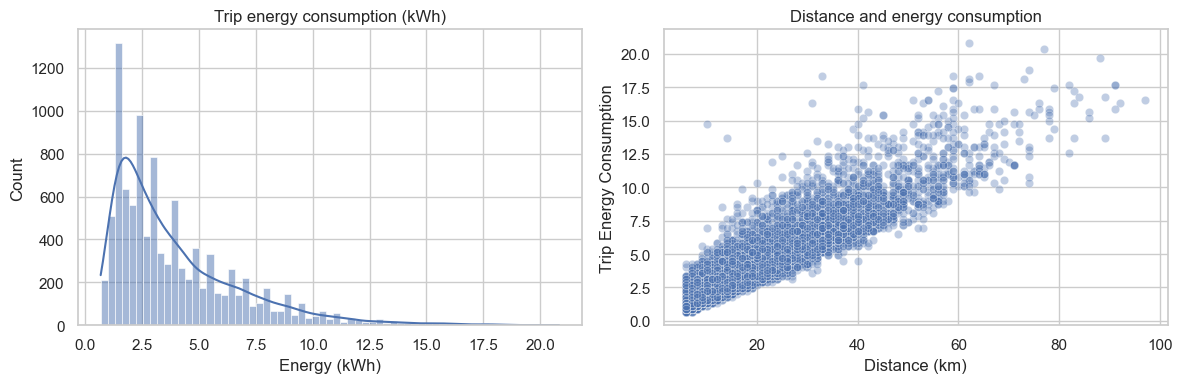

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(clean_data[TARGET], kde=True, ax=axes[0])
axes[0].set_title("Trip energy consumption (kWh)")
axes[0].set_xlabel("Energy (kWh)")
sns.scatterplot(data=clean_data, x="Trip Distance", y=TARGET, alpha=.35, ax=axes[1])
axes[1].set_title("Distance and energy consumption")
axes[1].set_xlabel("Distance (km)")
plt.tight_layout()
plt.show()

**Result:** The histogram and scatter plot are displayed above. The scatter plot shows energy generally rising with trip distance, though the points vary. This is an association, not proof that distance alone determines energy.

**Next:** Quantify linear associations as a descriptive check.

In [11]:
correlation = clean_data.select_dtypes(include="number").corr()[TARGET].sort_values(ascending=False)
correlation

Trip Energy Consumption                1.000000
Trip Distance                          0.915284
Trip Time Length                       0.256830
Current                                0.134976
Maximum Cell Temperature of Battery    0.094071
Vehicle ID                             0.081833
Minimum Cell Temperature of Battery    0.068034
Speed                                  0.034594
Day of the Week                        0.023650
Longitude                             -0.001871
Latitude                              -0.019821
Total Voltage                         -0.098066
Time of Day                           -0.117176
Name: Trip Energy Consumption, dtype: float64

**Result:** Distance has the strongest linear correlation with energy (**0.915**). Trip duration is **0.257**; remaining inputs are much weaker. Duration is excluded because it is only known after the trip. Correlation does not establish cause.

**Next:** Keep only features available before departure.

## 5. Choose features for the pre-trip scenario
Use planned trip distance, cyclic departure-time features, day of week, and vehicle ID. Exclude speed, current, voltage, battery temperatures, trip duration, and average coordinates because they are measured during or after the trip. Treat vehicle ID and weekday as categories, not continuous numbers.

## Feature engineering: represent time of day cyclically
Hours wrap around at midnight: 23:00 is close to 00:00, even though the raw numbers look far apart. Create sine and cosine features from the departure hour to represent this cycle. Both values are known before departure.

In [12]:
clean_data["Departure Time Sin"] = np.sin(2 * np.pi * clean_data["Time of Day"] / 24)
clean_data["Departure Time Cos"] = np.cos(2 * np.pi * clean_data["Time of Day"] / 24)
print(clean_data[["Time of Day", "Departure Time Sin", "Departure Time Cos"]].head())

   Time of Day  Departure Time Sin  Departure Time Cos
0    10.333333            0.422618           -0.906308
1    16.000000           -0.866025           -0.500000
2    16.090909           -0.877679           -0.479249
3    19.000000           -0.965926            0.258819
4    14.166667           -0.537300           -0.843391


**Result:** The new values stay between -1 and 1 and place late-night and early-morning hours close together on a circle. This is a justified feature transformation of departure time, not a value derived from the target.

**Next:** Use these two features in place of the raw hour.

In [13]:
candidate_features = ["Trip Distance", "Departure Time Sin", "Departure Time Cos", "Day of the Week", "Vehicle ID"]
features = [column for column in candidate_features if column in clean_data.columns]
print("Features used:", features)
print("Target:", TARGET)

Features used: ['Trip Distance', 'Departure Time Sin', 'Departure Time Cos', 'Day of the Week', 'Vehicle ID']
Target: Trip Energy Consumption


**Result:** The model uses **Trip Distance, Departure Time Sin, Departure Time Cos, Day of the Week, and Vehicle ID**. Cyclic time features preserve the fact that late night and early morning are close in time. Other trip measurements and average coordinates are excluded to avoid using information unavailable before departure.

**Next:** Split by vehicle so the same vehicle is not used in both training and test.

## 6. Create training and test sets
A vehicle-based split tests whether the model can work on vehicles not seen during training. The test set is kept separate until the final evaluation.

In [14]:
X = clean_data[features].copy()
y = clean_data[TARGET].copy()
groups = X["Vehicle ID"].astype(str) if "Vehicle ID" in X.columns else None

if groups is not None and groups.nunique() >= 2:
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
    train_index, test_index = next(splitter.split(X, y, groups=groups))
    split_note = "Split by vehicle group"
else:
    from sklearn.model_selection import train_test_split
    train_index, test_index = train_test_split(np.arange(len(X)), test_size=0.20, random_state=RANDOM_STATE)
    split_note = "Random split (not enough vehicle groups)"

X_train, X_test = X.iloc[train_index].copy(), X.iloc[test_index].copy()
y_train, y_test = y.iloc[train_index].copy(), y.iloc[test_index].copy()
groups_train = groups.iloc[train_index] if groups is not None else None
print(split_note)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
if groups is not None:
    print("Vehicles overlap:", bool(set(groups.iloc[train_index]) & set(groups.iloc[test_index])))

Split by vehicle group
Training rows: 7989
Test rows: 2162
Vehicles overlap: False


**Result:** Training has **7,989 rows**, and test has **2,162 rows**. The vehicle overlap is **False**, so this test evaluates performance on vehicles held out from training.

**Next:** Set up imputation, scaling, and categorical encoding within each model pipeline.

## 7. Prepare the data for modeling
Fill numeric gaps with the training median, and categorical gaps with the most common training value. One-hot encode vehicle ID and weekday. Standardize numeric inputs for Ridge regression. These steps are placed inside each model pipeline so they are learned from training data only.

In [15]:
categorical_features = [c for c in ["Vehicle ID", "Day of the Week"] if c in features]
numeric_features = [c for c in features if c not in categorical_features]

try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

numeric_scaled = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
numeric_plain = Pipeline([("imputer", SimpleImputer(strategy="median"))])
categorical_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", encoder)])

def make_preprocessor(scale_numeric=False):
    return ColumnTransformer([
        ("numeric", numeric_scaled if scale_numeric else numeric_plain, numeric_features),
        ("categorical", categorical_pipe, categorical_features),
    ])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['Trip Distance', 'Departure Time Sin', 'Departure Time Cos']
Categorical features: ['Vehicle ID', 'Day of the Week']


**Result:** Trip distance and the two departure-time features are numeric. Vehicle ID and day of week are categories and are one-hot encoded. Ridge scales numeric features; tree models do not need scaling.

**Next:** Compare candidate models with grouped cross-validation on training data.

## 8. Compare candidate models
Use cross-validation grouped by vehicle on the training set to select the model with the lowest mean absolute error (MAE). The test set is not used for selection.

In [16]:
model_options = {
    "Baseline": (DummyRegressor(strategy="mean"), False),
    "Ridge": (Ridge(), True),
    "Random Forest": (RandomForestRegressor(n_estimators=120, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=1), False),
    "Extra Trees": (ExtraTreesRegressor(n_estimators=120, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1), False),
    "Hist Gradient Boosting": (HistGradientBoostingRegressor(random_state=RANDOM_STATE), False),
}

if groups_train is not None and groups_train.nunique() >= 2:
    cv = GroupKFold(n_splits=min(3, groups_train.nunique()))
    cv_groups = groups_train
else:
    from sklearn.model_selection import KFold
    cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    cv_groups = None

models = {}
cv_rows = []
for name, (estimator, scale) in model_options.items():
    model = Pipeline([("preprocess", make_preprocessor(scale)), ("model", estimator)])
    scores = cross_val_score(model, X_train, y_train, scoring="neg_mean_absolute_error", cv=cv, groups=cv_groups, n_jobs=-1)
    model.fit(X_train, y_train)
    models[name] = model
    cv_rows.append({"Model": name, "Cross-validation MAE (kWh)": -scores.mean()})

cv_results = pd.DataFrame(cv_rows).sort_values("Cross-validation MAE (kWh)")
display(cv_results)
best_name = cv_results.iloc[0]["Model"]
best_model = models[best_name]
print("Selected by training cross-validation:", best_name)

,Model,Cross-validation MAE (kWh)
1,Ridge,0.733849
2,Random Forest,0.753608
4,Hist Gradient Boosting,0.766521
3,Extra Trees,0.767173
0,Baseline,2.121196


Selected by training cross-validation: Ridge


**Result:** With the engineered time features, Ridge has the lowest grouped cross-validation MAE (**0.7338 kWh**), followed by Random Forest (**0.7536**), Hist Gradient Boosting (**0.7665**), Extra Trees (**0.7672**), and the baseline (**2.1212**). Ridge is the current candidate before Random Forest tuning.

**Next:** Tune the Random Forest on training data only, then select using the same cross-validation results.

## Tune the Random Forest
The first comparison uses standard settings for each algorithm. Tune a small set of Random Forest settings using 3-fold grouped cross-validation on training data only. The held-out test set remains untouched.

In [17]:
rf_pipeline = Pipeline([
    ("preprocess", make_preprocessor(False)),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1)),
])
parameter_grid = {
    "model__n_estimators": [100],
    "model__max_depth": [None, 16],
    "model__min_samples_leaf": [1, 3],
}
rf_search = GridSearchCV(rf_pipeline, parameter_grid, scoring="neg_mean_absolute_error", cv=cv, n_jobs=1, refit=True)
rf_search.fit(X_train, y_train, groups=cv_groups)
tuned_rf = rf_search.best_estimator_
tuned_cv_mae = -rf_search.best_score_
models["Tuned Random Forest"] = tuned_rf
cv_results = pd.concat([cv_results, pd.DataFrame([{"Model": "Tuned Random Forest", "Cross-validation MAE (kWh)": tuned_cv_mae}])], ignore_index=True)
cv_results = cv_results.sort_values("Cross-validation MAE (kWh)").reset_index(drop=True)
best_name = cv_results.iloc[0]["Model"]
best_model = models[best_name]
display(cv_results)
print("Best Random Forest parameters:", rf_search.best_params_)
print("Selected model after tuning:", best_name)

,Model,Cross-validation MAE (kWh)
0,Ridge,0.733849
1,Tuned Random Forest,0.740540
2,Random Forest,0.753608
3,Hist Gradient Boosting,0.766521
4,Extra Trees,0.767173
5,Baseline,2.121196


Best Random Forest parameters: {'model__max_depth': 16, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
Selected model after tuning: Ridge


**Result:** Tuning improves Random Forest CV MAE from **0.7536 to 0.7405 kWh** (about 1.7%). Ridge remains the selected model because its grouped CV MAE is **0.7338**, lower than the tuned forest. This model choice is made without looking at test results.

**Next:** Evaluate every original and tuned candidate on the held-out test vehicles.

## 9. Final model evaluation
MAE is the average absolute error in kWh. RMSE penalizes large errors more strongly. R² compares predictions with a mean-value baseline; it can be negative when predictions are poor.

In [18]:
test_rows = []
test_predictions = {}
for name, model in models.items():
    prediction = model.predict(X_test)
    test_predictions[name] = prediction
    test_rows.append({
        "Model": name,
        "MAE (kWh)": mean_absolute_error(y_test, prediction),
        "RMSE (kWh)": np.sqrt(mean_squared_error(y_test, prediction)),
        "R2": r2_score(y_test, prediction),
    })

test_results = pd.DataFrame(test_rows).sort_values("MAE (kWh)")
display(test_results)
print("Selected model:", best_name)
print("Test MAE:", round(mean_absolute_error(y_test, best_model.predict(X_test)), 4), "kWh")

,Model,MAE (kWh),RMSE (kWh),R2
5,Tuned Random Forest,0.828106,1.223628,0.822730
1,Ridge,0.833613,1.218046,0.824343
2,Random Forest,0.848905,1.237775,0.818607
3,Extra Trees,0.857505,1.247653,0.815700
4,Hist Gradient Boosting,0.861630,1.225358,0.822228
0,Baseline,2.230748,2.948999,-0.029642


Selected model: Ridge
Test MAE: 0.8336 kWh


**Result:** Ridge, selected by grouped CV, achieves test **MAE 0.8336 kWh**, **RMSE 1.2180 kWh**, and **R² 0.8243**. This is better than the baseline MAE (**2.2307 kWh**). The tuned Random Forest has the lowest test MAE (**0.8281 kWh**) but was not selected because its CV MAE was higher; choosing from test results would tune to the test set. It has RMSE 1.2236 and R² 0.8227.

**Next:** Inspect the selected Ridge model's prediction and error plots.

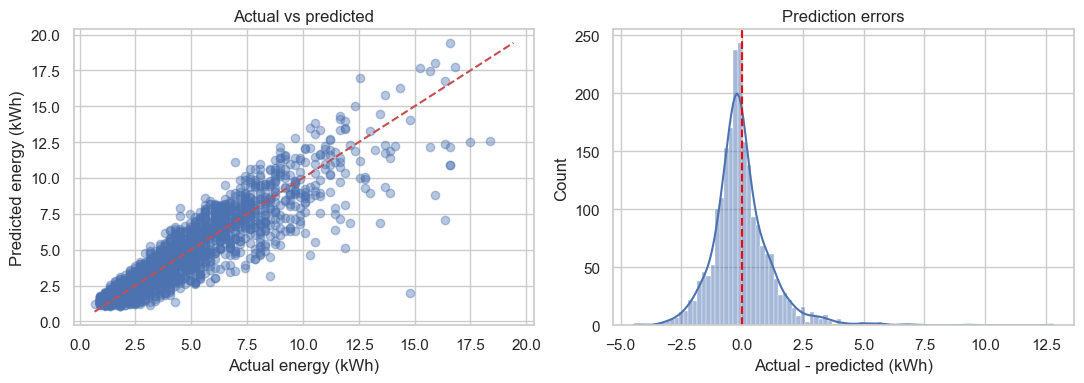

Mean error (kWh): -0.0148


In [19]:
best_prediction = best_model.predict(X_test)
error = y_test.to_numpy() - best_prediction
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, best_prediction, alpha=.4)
low = min(y_test.min(), best_prediction.min())
high = max(y_test.max(), best_prediction.max())
axes[0].plot([low, high], [low, high], "r--")
axes[0].set(xlabel="Actual energy (kWh)", ylabel="Predicted energy (kWh)", title="Actual vs predicted")
sns.histplot(error, kde=True, ax=axes[1])
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set(xlabel="Actual - predicted (kWh)", title="Prediction errors")
plt.tight_layout()
plt.show()
print("Mean error (kWh):", round(error.mean(), 4))

**Result:** The actual-versus-predicted and error plots are shown above. The mean signed error is **-0.0148 kWh**, close to zero, so the selected Ridge model has little average over/under-estimation on this test set. Individual trips can still have larger errors.

**Next:** Check which inputs matter most to the selected model's test error.

,Feature,MAE increase when shuffled
0,Trip Distance,2.228524
2,Departure Time Cos,0.061447
1,Departure Time Sin,0.019192
3,Day of the Week,0.001691
4,Vehicle ID,0.000000


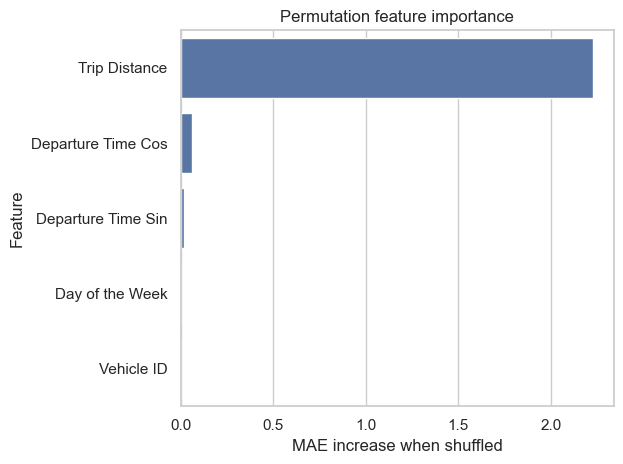

In [20]:
importance = permutation_importance(best_model, X_test, y_test, scoring="neg_mean_absolute_error", n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
importance_table = pd.DataFrame({"Feature": features, "MAE increase when shuffled": importance.importances_mean}).sort_values("MAE increase when shuffled", ascending=False)
display(importance_table)
sns.barplot(data=importance_table, x="MAE increase when shuffled", y="Feature")
plt.title("Permutation feature importance")
plt.tight_layout()
plt.show()

**Result:** Trip distance is the dominant input: shuffling it increases MAE by **2.2285 kWh**. Departure-time cosine adds **0.0614**, sine adds **0.0192**, weekday adds **0.0017**, and vehicle ID adds **0.0000**. These values describe this model and test set, not causal effects.

**Next:** Confirm the processed matrix is numeric, has no missing values, and has no vehicle overlap.

## 10. Final modeling-readiness check
The milestone requires numeric, encoded features and a leak-free finalized split. Inspect the transformed training matrix from the selected model's preprocessing pipeline. For tree models, numeric scaling is not necessary; categorical values are one-hot encoded and the resulting matrix must contain only numeric, non-missing values.

In [21]:
prepared_train = best_model.named_steps["preprocess"].transform(X_train)
prepared_names = best_model.named_steps["preprocess"].get_feature_names_out()
print("Prepared training shape:", prepared_train.shape)
print("Feature names:", list(prepared_names))
print("All values numeric:", np.issubdtype(prepared_train.dtype, np.number))
print("Missing values after preprocessing:", int(np.isnan(prepared_train).sum()))
if groups is not None:
    overlap = set(groups.iloc[train_index]) & set(groups.iloc[test_index])
    print("Vehicle overlap between train and test:", len(overlap))
print("Clean dataset saved at:", cleaned_path.resolve())

Prepared training shape: (7989, 50)
Feature names: ['numeric__Trip Distance', 'numeric__Departure Time Sin', 'numeric__Departure Time Cos', 'categorical__Vehicle ID_1.0', 'categorical__Vehicle ID_2.0', 'categorical__Vehicle ID_3.0', 'categorical__Vehicle ID_4.0', 'categorical__Vehicle ID_5.0', 'categorical__Vehicle ID_6.0', 'categorical__Vehicle ID_7.0', 'categorical__Vehicle ID_9.0', 'categorical__Vehicle ID_10.0', 'categorical__Vehicle ID_11.0', 'categorical__Vehicle ID_12.0', 'categorical__Vehicle ID_13.0', 'categorical__Vehicle ID_14.0', 'categorical__Vehicle ID_15.0', 'categorical__Vehicle ID_16.0', 'categorical__Vehicle ID_17.0', 'categorical__Vehicle ID_18.0', 'categorical__Vehicle ID_19.0', 'categorical__Vehicle ID_20.0', 'categorical__Vehicle ID_22.0', 'categorical__Vehicle ID_23.0', 'categorical__Vehicle ID_24.0', 'categorical__Vehicle ID_26.0', 'categorical__Vehicle ID_28.0', 'categorical__Vehicle ID_29.0', 'categorical__Vehicle ID_30.0', 'categorical__Vehicle ID_31.0', 'cat

**Result:** The selected Ridge pipeline transforms the training set into **7,989 rows and 50 numeric columns**. It has **0 missing values**, and the vehicle overlap between training and test is **0**. Numeric features are standardized inside the Ridge pipeline; categorical variables are one-hot encoded. The cleaned CSV is saved under Data.

**Next:** Use the findings and model metrics in the milestone presentation.

## 11. Conclusion

The selected model is **Ridge**, chosen by grouped cross-validation. On held-out vehicles it achieves **MAE 0.8336 kWh, RMSE 1.2180 kWh, and R² 0.8243**. Its MAE is about **62.6% lower** than the mean baseline's 2.2307 kWh. A tuned Random Forest improved its own CV MAE from 0.7536 to 0.7405 kWh and test MAE from 0.8489 to 0.8281 kWh, but Ridge remains the selected model because it had lower CV error.

**Business insight:** Trip distance is the strongest signal in both correlation analysis (0.915) and permutation importance. This supports prioritizing route distance in a pre-trip estimate; it does not prove causation. Departure time adds a smaller contribution, while weekday and vehicle ID add little in this held-out-vehicle test.

**Limitations:** The data is historical and limited to the vehicles and conditions represented. The source documentation says about 10,000 trips while the supplied CSV has 10,201 rows; this difference is documented and should be checked with the source. The model is a prototype, not a guaranteed range or safety estimate. The pre-trip scenario deliberately excludes measurements only available after departure.

### Milestone coverage
- **Milestone 1:** Problem, objectives, dataset source, target, feature descriptions, and working initial data load are documented above.
- **Milestone 2:** Dataset overview, missing/duplicate checks, cleaning decisions, before/after counts, outlier review, and the clean CSV deliverable are included.
- **Milestone 3:** EDA charts, business insight, correlation interpretation, feature engineering, leakage-aware preprocessing/splitting, model comparison/tuning, and a final readiness check are included. This notebook combines EDA and preprocessing; use its results in the separate course presentation and repository submission.